In [41]:
import numpy as np
import pandas as pd
import xarray as xr 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

In [49]:
plotdir = "/home/kperny/VolMIP_stratosphere/plots/NAM/"
piControl = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/diagnostics_piControl.csv")
#df_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nao_flags.csv")
nam_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nam_flags.csv")
models = nam_flags['model'].unique()

piControl[nam_flags.columns[1:]] = nam_flags[nam_flags.columns[1:]]

### SURFACE

In [50]:
df_flags = nam_flags.set_index(['model', 'realization']).drop(['year', 'nam_10_pi', 'nam_10_volc', 'flag_10_pi', 'flag_10_volc'], axis=1)
df_flags['count'] = 1
# get amount of realizations of each NAO state in piControl
df_out = df_flags.groupby(['model', 'flag_1000_pi']).sum()
df_out = df_out.reset_index().set_index('flag_1000_pi')
df_out = df_out.drop(['nam_1000_pi', 'nam_1000_volc', 'flag_1000_volc'], axis=1)
df_rel_new = df_out.copy()

# create index based on NAO state for piControl
naon = df_flags.where(df_flags['flag_1000_pi'] == -1).dropna().index
naop = df_flags.where(df_flags['flag_1000_pi'] == 1).dropna().index
nao0 = df_flags.where(df_flags['flag_1000_pi'] == 0).dropna().index


# iterate over NAO state and count state changes in volc
states = ['NAM-', 'NAM0', 'NAM+']
for idx, value in zip([naon, naop, nao0], [-1, 1, 0]):
    volc = df_flags.loc[idx].drop(columns=['nam_1000_pi', 'nam_1000_volc', 'flag_1000_pi'])
    df_out.loc[value, states] = volc.groupby(['model', 'flag_1000_volc']).sum().unstack().values
    df_rel_new.loc[value, states] = volc.groupby(['model', 'flag_1000_volc']).sum().unstack().values / df_out.reset_index().set_index(['flag_1000_pi', 'model']).loc[value]['count'].values.reshape(6,1)

df_nao = df_out.reset_index().set_index(['flag_1000_pi', 'model']).sort_index()
df_nao = df_nao.fillna(0)

df_rel = df_rel_new.reset_index().set_index(['flag_1000_pi', 'model']).sort_index()
df_rel = df_rel.fillna(0)

# calculate percantage and round to integer
df_pro = df_rel.copy()
df_pro[states] = df_pro[states] *100

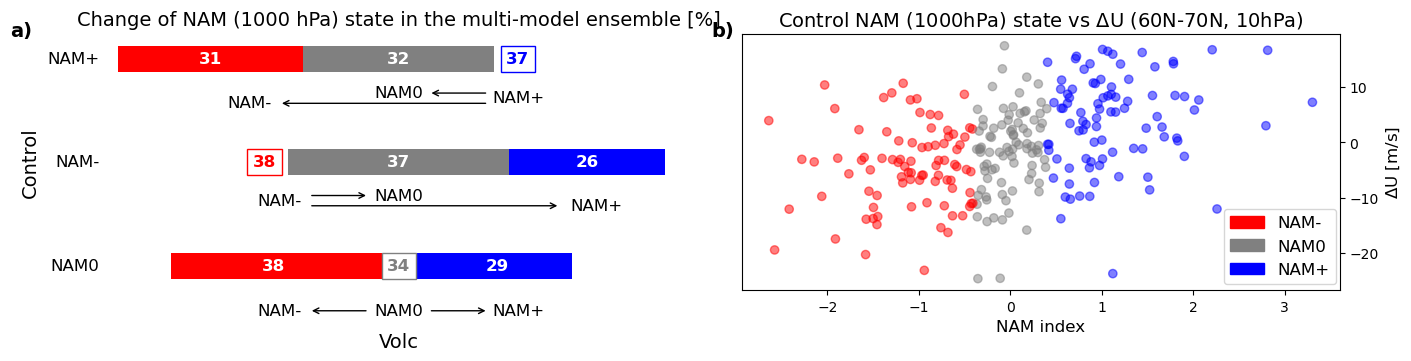

In [51]:
fig, axes = plt.subplots(1,2, figsize=(14,3.5), layout='constrained')

###### FIGURE B
axes[1].set_title('Control NAM (1000hPa) state vs $\Delta$U (60N-70N, 10hPa)', fontsize=14)
axes[1].scatter(piControl['nam_1000_pi'], piControl['deltaU'], c=piControl['flag_1000_pi'].map({-1: 'red', 0: 'grey', 1: 'blue'}), alpha=0.5)
axes[1].set_ylabel('$\Delta$U [m/s]',fontsize=12)
axes[1].set_xlabel('NAM index', fontsize=12)
# Move ticks marks and tick labels
axes[1].tick_params(
    right=True, labelright=True,
    left=False, labelleft=False,
)
# Move axis labels
axes[1].yaxis.set_label_position("right")
axes[1].annotate('b)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')

###### FIGURE A

axs = axes[0]
data = df_pro.groupby(['flag_1000_pi']).mean().round(0).apply(pd.to_numeric, downcast='integer')

axs.barh('NAM0', -data.loc[0]['NAM-'], height=0.25, color = 'r')
axs.barh('NAM0', data.loc[0]['NAM+'], height=0.25, color = 'b')

axs.barh('NAM-', data.loc[-1]['NAM+'] + data.loc[-1]['NAM0'] / 2, height=0.25, color = 'b')
axs.barh('NAM-', -data.loc[-1]['NAM0']/ 2, height=0.25, color = 'grey')
axs.barh('NAM-', data.loc[-1]['NAM0'] / 2, height=0.25, color = 'grey')

axs.barh('NAM+', -data.loc[1]['NAM-'] - data.loc[1]['NAM0'] / 2, height=0.25, color = 'r')
axs.barh('NAM+', -data.loc[1]['NAM0']/ 2, height=0.25, color = 'grey')
axs.barh('NAM+', data.loc[1]['NAM0'] / 2, height=0.25, color = 'grey')


axs.set_xlim(-50, 50)
# Annnotate piControl NAO+
axs.annotate(data.loc[1]['NAM-'], xy=( - data.loc[1]['NAM0'] / 2 - data.loc[1]['NAM-'] / 2, 'NAM+'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[1]['NAM0'], xy=(0, 'NAM+'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[1]['NAM+'], xy=(data.loc[1]['NAM0'] / 2 + 2, 'NAM+'), xycoords='data', ha='left', va='center',
             fontsize=12, weight='bold', color='b', bbox=dict(fc='white', ec='b'))

# Annotate piControl NAO-
axs.annotate(data.loc[-1]['NAM-'], xy=(- data.loc[-1]['NAM0'] / 2 - 2, 'NAM-'), xycoords='data', ha='right', va='center',
             fontsize=12, weight='bold', color='r', bbox=dict(fc='white', ec='r'))
axs.annotate(data.loc[-1]['NAM0'], xy=(0, 'NAM-'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[-1]['NAM+'], xy=(data.loc[-1]['NAM0'] / 2 + data.loc[-1]['NAM+'] / 2, 'NAM-'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')

# Annnotate piControl NAO0
axs.annotate(data.loc[0]['NAM-'], xy=(- data.loc[0]['NAM-'] / 2 - 2, 'NAM0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[0]['NAM0'], xy=(0, 'NAM0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='grey', bbox=dict(fc='white', ec='grey'))
axs.annotate(data.loc[0]['NAM+'], xy=(data.loc[0]['NAM+'] / 2 + 2, 'NAM0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')

# axis labels
axs.set_axis_off()
axs.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
        arrowprops=dict(arrowstyle="<-", color='k'))
axs.annotate('', xy=(0.45, 0.37), xycoords='axes fraction', xytext=(0.35, 0.37), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.77, 0.33), xycoords='axes fraction', xytext=(0.35, 0.33), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.65, 0.77), xycoords='axes fraction', xytext=(0.55, 0.77), 
        arrowprops=dict(arrowstyle="<-", color='k'))
axs.annotate('', xy=(0.65, 0.73), xycoords='axes fraction', xytext=(0.3, 0.73), 
        arrowprops=dict(arrowstyle="<-", color='k'))

axs.annotate('NAM0', xy=(0.5, 0.77), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM0', xy=(0.5, 0.37), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM-', xy=(0.25, 0.73), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM-', xy=(0.3, 0.35), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM+', xy=(0.7, 0.75), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM+', xy=(0.83, 0.33), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')

axs.annotate('NAM-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('Volc', xy=(0.5, -0.2), xycoords='axes fraction', ha='center', va='center', fontsize=14, color='k')

# ylabels
axs.annotate('NAM+', xy=(-50, 'NAM+'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('NAM-', xy=(-50, 'NAM-'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('NAM0', xy=(-50, 'NAM0'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('Control', xy=(-60, 'NAM-'), xycoords='data', ha='right', va='center', fontsize=14, color='k', rotation=90, annotation_clip=False)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAM+')
green_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='red', label='NAM-')

fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(0.91,0.31))

axs.set_title('Change of NAM (1000 hPa) state in the multi-model ensemble [%]', fontsize=14)
axs.annotate('a)', fontsize=14, weight='bold', color='k', xy=(-0.15, 1.05), xycoords='axes fraction', ha='left', va='top')
plt.savefig(plotdir + 'figure1_1000.png', dpi=200, bbox_inches='tight')

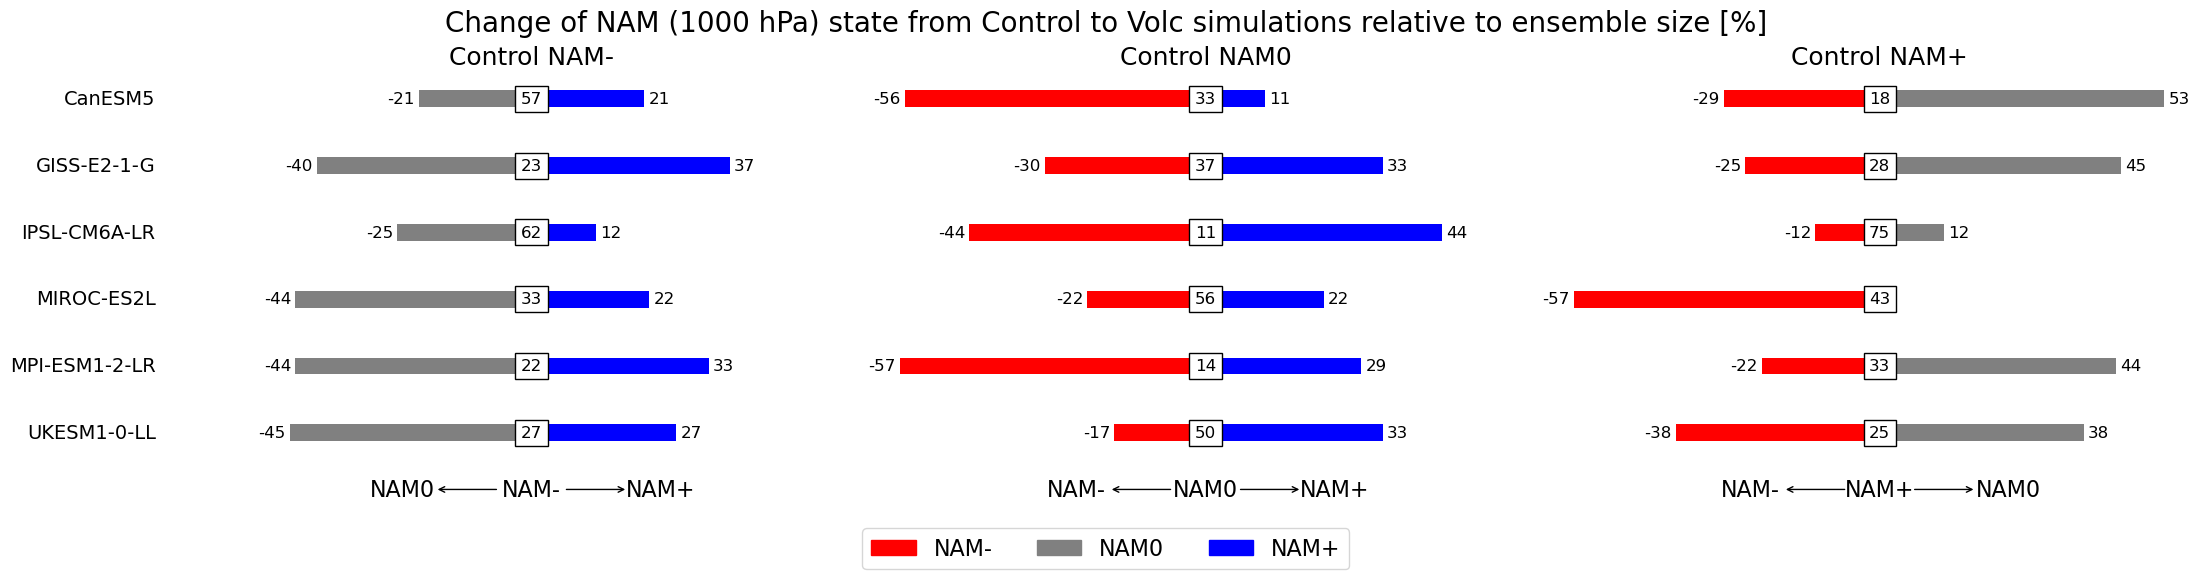

In [52]:
df_pro = df_pro.round(0).apply(pd.to_numeric, downcast='integer')

fig, axs = plt.subplots(1,3, figsize=(22, 5), sharey=True, layout='constrained')

data = df_pro.loc[-1].reset_index()
axs[0].barh(data['model'], data['NAM+'], height=0.25, color = 'b')
axs[0].barh(data['model'], -data['NAM0'], height=0.25, color = 'grey')

data = df_pro.loc[0].reset_index()
axs[1].barh(data['model'], -data['NAM-'], height=0.25, color = 'r')
axs[1].barh(data['model'], data['NAM+'], height=0.25, color = 'b')

data = df_pro.loc[1].reset_index()
axs[2].barh(data['model'], -data['NAM-'], height=0.25, color = 'r')
axs[2].barh(data['model'], data['NAM0'], height=0.25, color = 'grey')


for ax, nao, state, color in zip(axs, [-1,0,1], ['NAM-', 'NAM0', 'NAM+'], ['red', 'grey', 'blue']):
    ax.set_xlim(-60, 60)
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', padding=3, fontsize=12)
    for model in models:
        ax.annotate(df_pro.loc[nao, model][state], xy=(0, model), xycoords='data', ha='center', va='center',
                    fontsize=12, color='black', bbox=dict(fc='white'))
    # ax.set_xlabel(state, fontsize=16)
    ax.set_axis_off()
    ax.invert_yaxis()

    # ax.set_ylabel(data[model].values)
    ax.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
            arrowprops=dict(arrowstyle="->", color='k'))
    ax.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
            arrowprops=dict(arrowstyle="<-", color='k'))

# axs[0].tick_params(axis='both', labelsize=12)
    
axs[0].annotate('NAM0', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAM-', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAM+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[1].annotate('NAM-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAM0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAM+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[2].annotate('NAM-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAM+', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAM0', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

for i, model in enumerate(models):
    axs[0].annotate(model, xy=(-70,i), xycoords='data', ha='right', va='center', fontsize=14, color='k', annotation_clip=False)

axs[0].set_title('Control NAM-', fontsize=18)
axs[1].set_title('Control NAM0', fontsize=18)
axs[2].set_title('Control NAM+', fontsize=18)

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='red', label='NAM-')
green_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='blue', label='NAM+')
fig.legend(handles=[blue_patch, green_patch, red_patch], loc='lower center', ncol=3, fontsize=16, bbox_to_anchor=(0.5, -0.15))

plt.suptitle('Change of NAM (1000 hPa) state from Control to Volc simulations relative to ensemble size [%]', fontsize=20)
plt.savefig(plotdir + 'supp1_1000.png', dpi=200, bbox_inches='tight')

## 10hPA

In [53]:
df_flags = nam_flags.set_index(['model', 'realization']).drop(['year', 'nam_1000_pi', 'nam_1000_volc', 'flag_1000_pi', 'flag_1000_volc'], axis=1)
df_flags['count'] = 1
# get amount of realizations of each NAO state in piControl
df_out = df_flags.groupby(['model', 'flag_10_pi']).sum()
df_out = df_out.reset_index().set_index('flag_10_pi')
df_out = df_out.drop(['nam_10_pi', 'nam_10_volc', 'flag_10_volc'], axis=1)
df_rel_new = df_out.copy()

# create index based on NAO state for piControl
naon = df_flags.where(df_flags['flag_10_pi'] == -1).dropna().index
naop = df_flags.where(df_flags['flag_10_pi'] == 1).dropna().index
nao0 = df_flags.where(df_flags['flag_10_pi'] == 0).dropna().index


# iterate over NAO state and count state changes in volc
states = ['NAM-', 'NAM0', 'NAM+']
for idx, value in zip([naon, naop, nao0], [-1, 1, 0]):
    volc = df_flags.loc[idx].drop(columns=['nam_10_pi', 'nam_10_volc', 'flag_10_pi'])
    df_out.loc[value, states] = volc.groupby(['model', 'flag_10_volc']).sum().unstack().values
    df_rel_new.loc[value, states] = volc.groupby(['model', 'flag_10_volc']).sum().unstack().values / df_out.reset_index().set_index(['flag_10_pi', 'model']).loc[value]['count'].values.reshape(6,1)

df_nao = df_out.reset_index().set_index(['flag_10_pi', 'model']).sort_index()
df_nao = df_nao.fillna(0)

df_rel = df_rel_new.reset_index().set_index(['flag_10_pi', 'model']).sort_index()
df_rel = df_rel.fillna(0)

# calculate percantage and round to integer
df_pro = df_rel.copy()
df_pro[states] = df_pro[states] *100

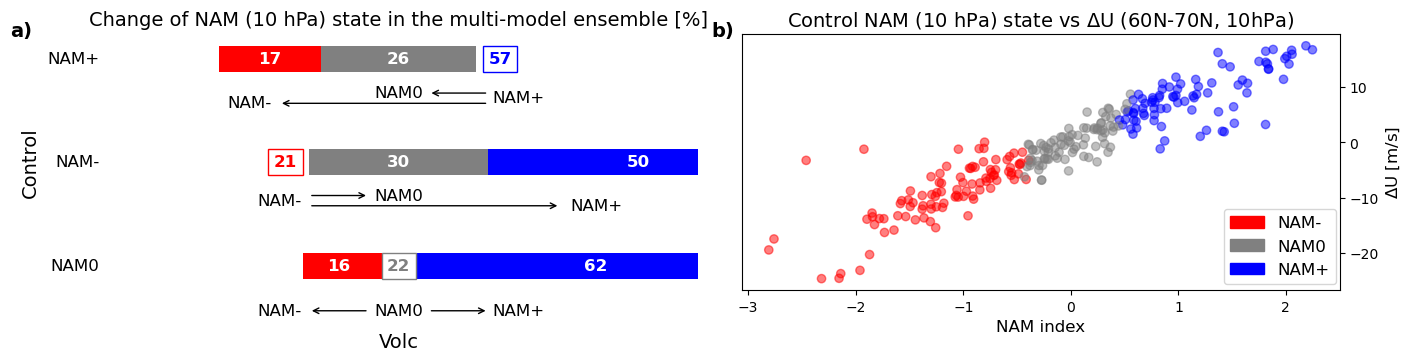

In [54]:
fig, axes = plt.subplots(1,2, figsize=(14,3.5), layout='constrained')

###### FIGURE B
axes[1].set_title('Control NAM (10 hPa) state vs $\Delta$U (60N-70N, 10hPa)', fontsize=14)
axes[1].scatter(piControl['nam_10_pi'], piControl['deltaU'], c=piControl['flag_10_pi'].map({-1: 'red', 0: 'grey', 1: 'blue'}), alpha=0.5)
axes[1].set_ylabel('$\Delta$U [m/s]',fontsize=12)
axes[1].set_xlabel('NAM index', fontsize=12)
# Move ticks marks and tick labels
axes[1].tick_params(
    right=True, labelright=True,
    left=False, labelleft=False,
)
# Move axis labels
axes[1].yaxis.set_label_position("right")
axes[1].annotate('b)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')

###### FIGURE A

axs = axes[0]
data = df_pro.groupby(['flag_10_pi']).mean().round(0).apply(pd.to_numeric, downcast='integer')

axs.barh('NAM0', -data.loc[0]['NAM-'], height=0.25, color = 'r')
axs.barh('NAM0', data.loc[0]['NAM+'], height=0.25, color = 'b')

axs.barh('NAM-', data.loc[-1]['NAM+'] + data.loc[-1]['NAM0'] / 2, height=0.25, color = 'b')
axs.barh('NAM-', -data.loc[-1]['NAM0']/ 2, height=0.25, color = 'grey')
axs.barh('NAM-', data.loc[-1]['NAM0'] / 2, height=0.25, color = 'grey')

axs.barh('NAM+', -data.loc[1]['NAM-'] - data.loc[1]['NAM0'] / 2, height=0.25, color = 'r')
axs.barh('NAM+', -data.loc[1]['NAM0']/ 2, height=0.25, color = 'grey')
axs.barh('NAM+', data.loc[1]['NAM0'] / 2, height=0.25, color = 'grey')


axs.set_xlim(-50, 50)
# Annnotate piControl NAO+
axs.annotate(data.loc[1]['NAM-'], xy=( - data.loc[1]['NAM0'] / 2 - data.loc[1]['NAM-'] / 2, 'NAM+'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[1]['NAM0'], xy=(0, 'NAM+'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[1]['NAM+'], xy=(data.loc[1]['NAM0'] / 2 + 2, 'NAM+'), xycoords='data', ha='left', va='center',
             fontsize=12, weight='bold', color='b', bbox=dict(fc='white', ec='b'))

# Annotate piControl NAO-
axs.annotate(data.loc[-1]['NAM-'], xy=(- data.loc[-1]['NAM0'] / 2 - 2, 'NAM-'), xycoords='data', ha='right', va='center',
             fontsize=12, weight='bold', color='r', bbox=dict(fc='white', ec='r'))
axs.annotate(data.loc[-1]['NAM0'], xy=(0, 'NAM-'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[-1]['NAM+'], xy=(data.loc[-1]['NAM0'] / 2 + data.loc[-1]['NAM+'] / 2, 'NAM-'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')

# Annnotate piControl NAO0
axs.annotate(data.loc[0]['NAM-'], xy=(- data.loc[0]['NAM-'] / 2 - 2, 'NAM0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')
axs.annotate(data.loc[0]['NAM0'], xy=(0, 'NAM0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='grey', bbox=dict(fc='white', ec='grey'))
axs.annotate(data.loc[0]['NAM+'], xy=(data.loc[0]['NAM+'] / 2 + 2, 'NAM0'), xycoords='data', ha='center', va='center',
             fontsize=12, weight='bold', color='white')

# axis labels
axs.set_axis_off()
axs.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
        arrowprops=dict(arrowstyle="<-", color='k'))
axs.annotate('', xy=(0.45, 0.37), xycoords='axes fraction', xytext=(0.35, 0.37), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.77, 0.33), xycoords='axes fraction', xytext=(0.35, 0.33), 
        arrowprops=dict(arrowstyle="->", color='k'))
axs.annotate('', xy=(0.65, 0.77), xycoords='axes fraction', xytext=(0.55, 0.77), 
        arrowprops=dict(arrowstyle="<-", color='k'))
axs.annotate('', xy=(0.65, 0.73), xycoords='axes fraction', xytext=(0.3, 0.73), 
        arrowprops=dict(arrowstyle="<-", color='k'))

axs.annotate('NAM0', xy=(0.5, 0.77), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM0', xy=(0.5, 0.37), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM-', xy=(0.25, 0.73), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM-', xy=(0.3, 0.35), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM+', xy=(0.7, 0.75), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM+', xy=(0.83, 0.33), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')

axs.annotate('NAM-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('NAM+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=12, color='k')
axs.annotate('Volc', xy=(0.5, -0.2), xycoords='axes fraction', ha='center', va='center', fontsize=14, color='k')

# ylabels
axs.annotate('NAM+', xy=(-50, 'NAM+'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('NAM-', xy=(-50, 'NAM-'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('NAM0', xy=(-50, 'NAM0'), xycoords='data', ha='right', va='center', fontsize=12, color='k', annotation_clip=False)
axs.annotate('Control', xy=(-60, 'NAM-'), xycoords='data', ha='right', va='center', fontsize=14, color='k', rotation=90, annotation_clip=False)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAM+')
green_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='red', label='NAM-')

fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(0.91,0.31))

axs.set_title('Change of NAM (10 hPa) state in the multi-model ensemble [%]', fontsize=14)
axs.annotate('a)', fontsize=14, weight='bold', color='k', xy=(-0.15, 1.05), xycoords='axes fraction', ha='left', va='top')
plt.savefig(plotdir + 'figure1_10.png', dpi=200, bbox_inches='tight')

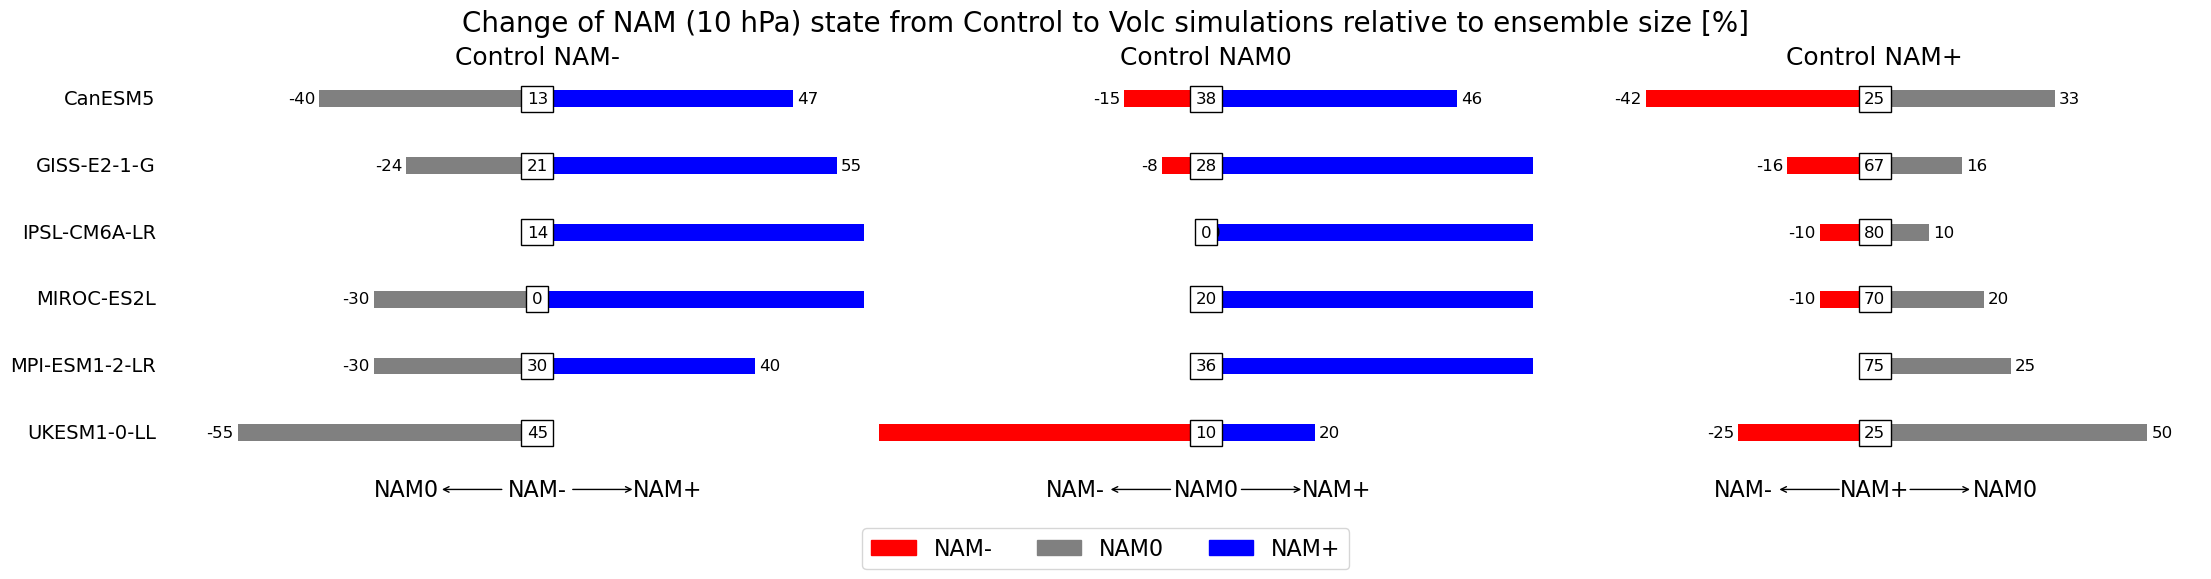

In [55]:
df_pro = df_pro.round(0).apply(pd.to_numeric, downcast='integer')

fig, axs = plt.subplots(1,3, figsize=(22, 5), sharey=True, layout='constrained')

data = df_pro.loc[-1].reset_index()
axs[0].barh(data['model'], data['NAM+'], height=0.25, color = 'b')
axs[0].barh(data['model'], -data['NAM0'], height=0.25, color = 'grey')

data = df_pro.loc[0].reset_index()
axs[1].barh(data['model'], -data['NAM-'], height=0.25, color = 'r')
axs[1].barh(data['model'], data['NAM+'], height=0.25, color = 'b')

data = df_pro.loc[1].reset_index()
axs[2].barh(data['model'], -data['NAM-'], height=0.25, color = 'r')
axs[2].barh(data['model'], data['NAM0'], height=0.25, color = 'grey')


for ax, nao, state, color in zip(axs, [-1,0,1], ['NAM-', 'NAM0', 'NAM+'], ['red', 'grey', 'blue']):
    ax.set_xlim(-60, 60)
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', padding=3, fontsize=12)
    for model in models:
        ax.annotate(df_pro.loc[nao, model][state], xy=(0, model), xycoords='data', ha='center', va='center',
                    fontsize=12, color='black', bbox=dict(fc='white'))
    # ax.set_xlabel(state, fontsize=16)
    ax.set_axis_off()
    ax.invert_yaxis()

    # ax.set_ylabel(data[model].values)
    ax.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
            arrowprops=dict(arrowstyle="->", color='k'))
    ax.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
            arrowprops=dict(arrowstyle="<-", color='k'))

# axs[0].tick_params(axis='both', labelsize=12)
    
axs[0].annotate('NAM0', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAM-', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAM+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[1].annotate('NAM-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAM0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAM+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[2].annotate('NAM-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAM+', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAM0', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

for i, model in enumerate(models):
    axs[0].annotate(model, xy=(-70,i), xycoords='data', ha='right', va='center', fontsize=14, color='k', annotation_clip=False)

axs[0].set_title('Control NAM-', fontsize=18)
axs[1].set_title('Control NAM0', fontsize=18)
axs[2].set_title('Control NAM+', fontsize=18)

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='red', label='NAM-')
green_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='blue', label='NAM+')
fig.legend(handles=[blue_patch, green_patch, red_patch], loc='lower center', ncol=3, fontsize=16, bbox_to_anchor=(0.5, -0.15))

plt.suptitle('Change of NAM (10 hPa) state from Control to Volc simulations relative to ensemble size [%]', fontsize=20)
plt.savefig(plotdir + 'supp1_10.png', dpi=200, bbox_inches='tight')

### SUPP 2

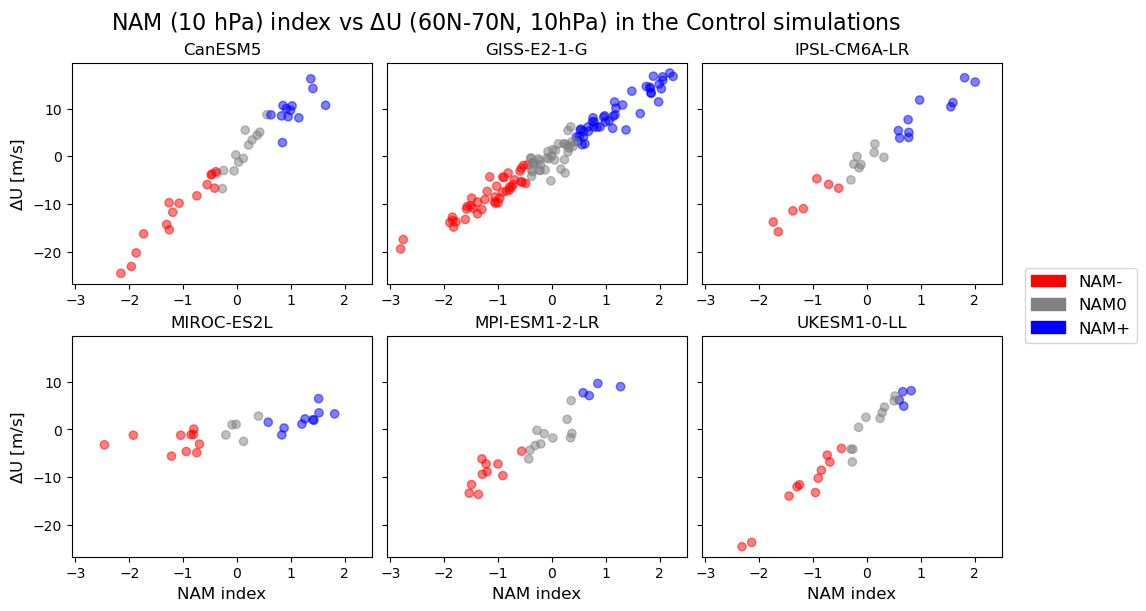

In [40]:
fig, axs = plt.subplots(2,3, figsize=(10,6), sharey=True, sharex=True, layout='constrained')

data = piControl.set_index(['model','realization'])
for ax, model in zip(axs.flat, models):
    tmp = data.loc[model]
    ax.scatter(tmp['nam_10_pi'], tmp['deltaU'], c=tmp['flag_10_pi'].map({-1: 'red', 0: 'grey', 1: 'blue'}), alpha=0.5)
    ax.set_title(model, fontsize=12)
#axs[-1,-1].set_axis_off()
fig.suptitle('NAM (10 hPa) index vs $\Delta$U (60N-70N, 10hPa) in the Control simulations', fontsize=16)
axs[0,0].set_ylabel('$\Delta$U [m/s]', fontsize=12)
axs[1,0].set_ylabel('$\Delta$U [m/s]', fontsize=12)
axs[1,0].set_xlabel('NAM index', fontsize=12)
axs[1,1].set_xlabel('NAM index', fontsize=12)
axs[1,2].set_xlabel('NAM index', fontsize=12)
axs[0,2].xaxis.set_tick_params(labelbottom=True)
axs[0,1].xaxis.set_tick_params(labelbottom=True)
axs[0,0].xaxis.set_tick_params(labelbottom=True)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAM+')
green_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='red', label='NAM-')

fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(1.075,0.5))


plt.savefig(plotdir + 'supp2_10.png', dpi=200, bbox_inches='tight')

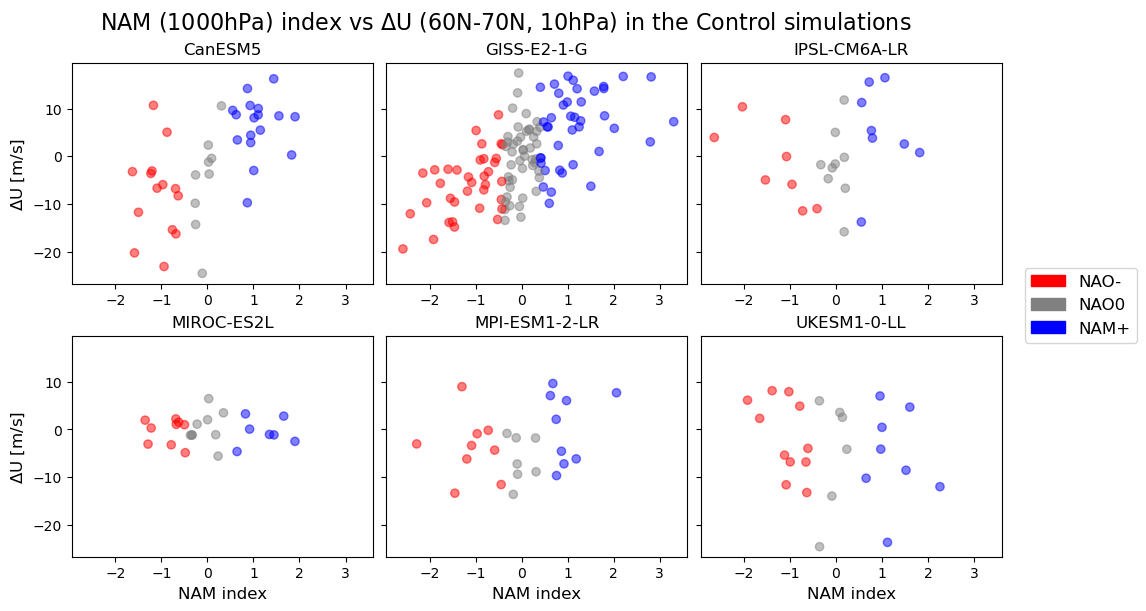

In [39]:
fig, axs = plt.subplots(2,3, figsize=(10,6), sharey=True, sharex=True, layout='constrained')

data = piControl.set_index(['model','realization'])
for ax, model in zip(axs.flat, models):
    tmp = data.loc[model]
    ax.scatter(tmp['nam_1000_pi'], tmp['deltaU'], c=tmp['flag_1000_pi'].map({-1: 'red', 0: 'grey', 1: 'blue'}), alpha=0.5)
    ax.set_title(model, fontsize=12)
#axs[-1,-1].set_axis_off()
fig.suptitle('NAM (1000hPa) index vs $\Delta$U (60N-70N, 10hPa) in the Control simulations', fontsize=16)
axs[0,0].set_ylabel('$\Delta$U [m/s]', fontsize=12)
axs[1,0].set_ylabel('$\Delta$U [m/s]', fontsize=12)
axs[1,0].set_xlabel('NAM index', fontsize=12)
axs[1,1].set_xlabel('NAM index', fontsize=12)
axs[1,2].set_xlabel('NAM index', fontsize=12)
axs[0,2].xaxis.set_tick_params(labelbottom=True)
axs[0,1].xaxis.set_tick_params(labelbottom=True)
axs[0,0].xaxis.set_tick_params(labelbottom=True)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAM+')
green_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO-')
    
fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(1.075,0.5))


plt.savefig(plotdir + 'supp2_1000.png', dpi=200, bbox_inches='tight')

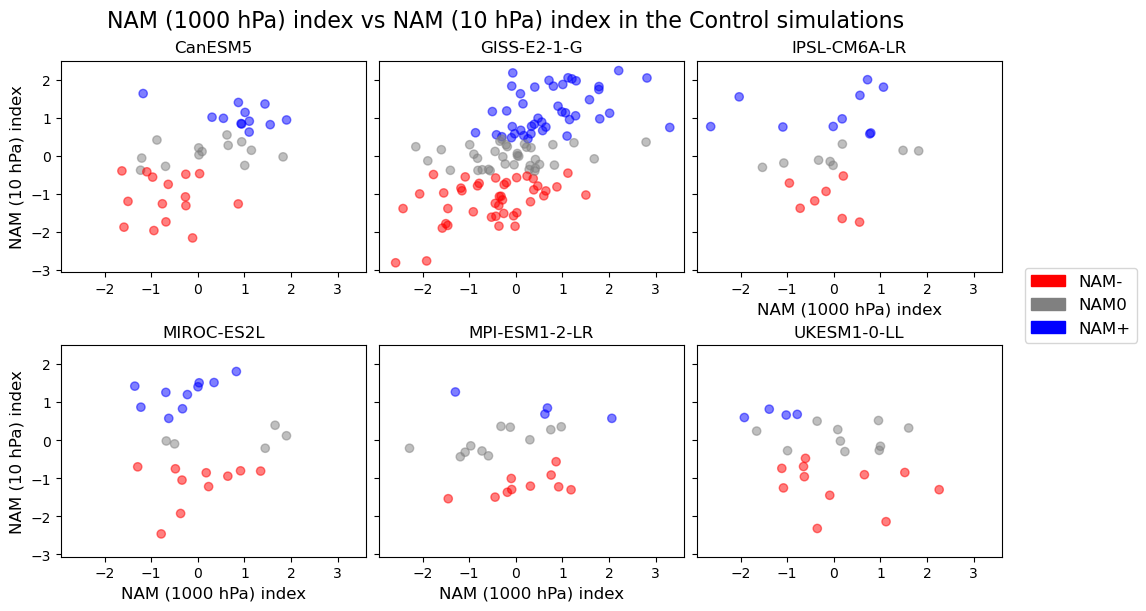

In [36]:
fig, axs = plt.subplots(2,3, figsize=(10,6), sharey=True, sharex=True, layout='constrained')

data = piControl.set_index(['model','realization'])
for ax, model in zip(axs.flat, models):
    tmp = data.loc[model]
    ax.scatter(tmp['nam_1000_pi'], tmp['nam_10_pi'], c=tmp['flag_10_pi'].map({-1: 'red', 0: 'grey', 1: 'blue'}), alpha=0.5)
    ax.set_title(model, fontsize=12)
#axs[-1,-1].set_axis_off()
fig.suptitle('NAM (1000 hPa) index vs NAM (10 hPa) index in the Control simulations', fontsize=16)
axs[0,0].set_ylabel('NAM (10 hPa) index', fontsize=12)
axs[1,0].set_ylabel('NAM (10 hPa) index', fontsize=12)
axs[1,0].set_xlabel('NAM (1000 hPa) index', fontsize=12)
axs[1,1].set_xlabel('NAM (1000 hPa) index', fontsize=12)
axs[0,2].set_xlabel('NAM (1000 hPa) index', fontsize=12)
axs[0,2].xaxis.set_tick_params(labelbottom=True)
axs[0,1].xaxis.set_tick_params(labelbottom=True)
axs[0,0].xaxis.set_tick_params(labelbottom=True)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAM+')
green_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='red', label='NAM-')

fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(1.075,0.5))


plt.savefig(plotdir + 'nam1000_vs_nam10.png', dpi=200, bbox_inches='tight')